# CT Noise Simulation

## Objective

Study the effect of noise in CT projection data on the quality of
filtered back projection reconstruction.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import iradon, radon

from medimaging.quality.psnr import calculate_psnr
from medimaging.quality.ssim import calculate_ssim
from medimaging.simulation.phantom import create_shepp_logan

## 1. Ideal Acquisition

We first generate a noise-free sinogram that will serve as the reference.

In [2]:
phantom = create_shepp_logan(256)

theta = np.linspace(
    0.0,
    180.0,
    180,
    endpoint=False,
)

sinogram = radon(
    phantom,
    theta=theta,
    circle=True,
)

reconstruction_clean = iradon(
    sinogram,
    theta=theta,
    filter_name="ramp",
    circle=True,
)

In [3]:
psnr_clean = calculate_psnr(phantom, reconstruction_clean)

ssim_clean = calculate_ssim(phantom, reconstruction_clean)

print(f"Clean PSNR: {psnr_clean:.2f} dB")
print(f"Clean SSIM: {ssim_clean:.4f}")

Clean PSNR: 30.77 dB
Clean SSIM: 0.9218


## 2. Additive Noise

Gaussian noise is added to the sinogram to simulate measurement
uncertainty in the projection data.

In [4]:
rng = np.random.default_rng(42) 
# Si utilizamos siempre la misma semilla, obtenemos el mismo ruido cada vez.

noise_std = 0.05

noise = rng.normal(
    loc=0.0,
    scale=noise_std,
    size=sinogram.shape,
)

sinogram_noisy = sinogram + noise

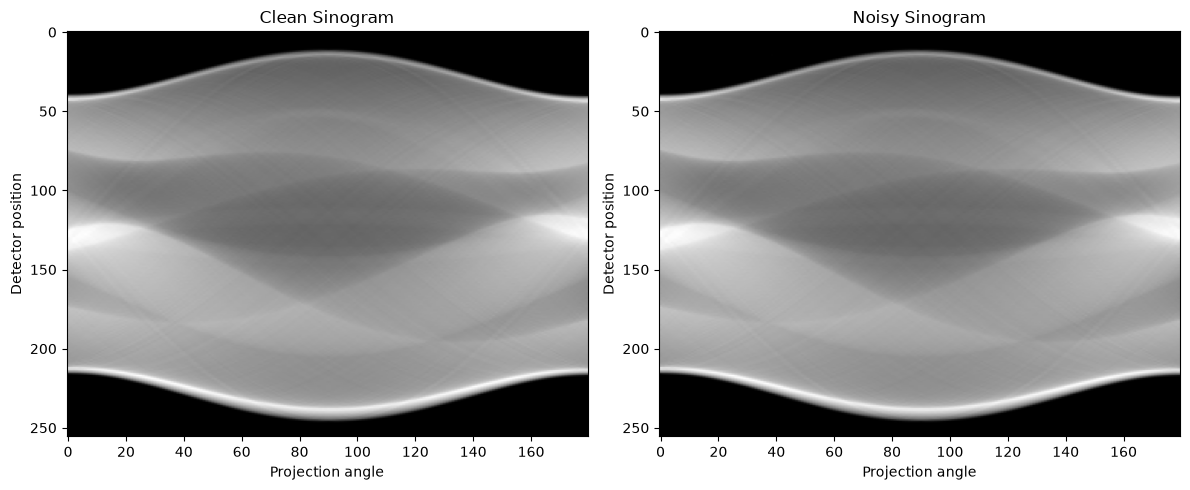

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    sinogram,
    cmap="gray",
    aspect="auto",
)
axes[0].set_title("Clean Sinogram")
axes[0].set_xlabel("Projection angle")
axes[0].set_ylabel("Detector position")

axes[1].imshow(
    sinogram_noisy,
    cmap="gray",
    aspect="auto",
)
axes[1].set_title("Noisy Sinogram")
axes[1].set_xlabel("Projection angle")
axes[1].set_ylabel("Detector position")

plt.tight_layout()
plt.show()

## 3. Reconstruction from Noisy Projections

The noisy sinogram is reconstructed using the same FBP algorithm.

In [6]:
reconstruction_noisy = iradon(
    sinogram_noisy,
    theta=theta,
    filter_name="ramp",
    circle=True,
)

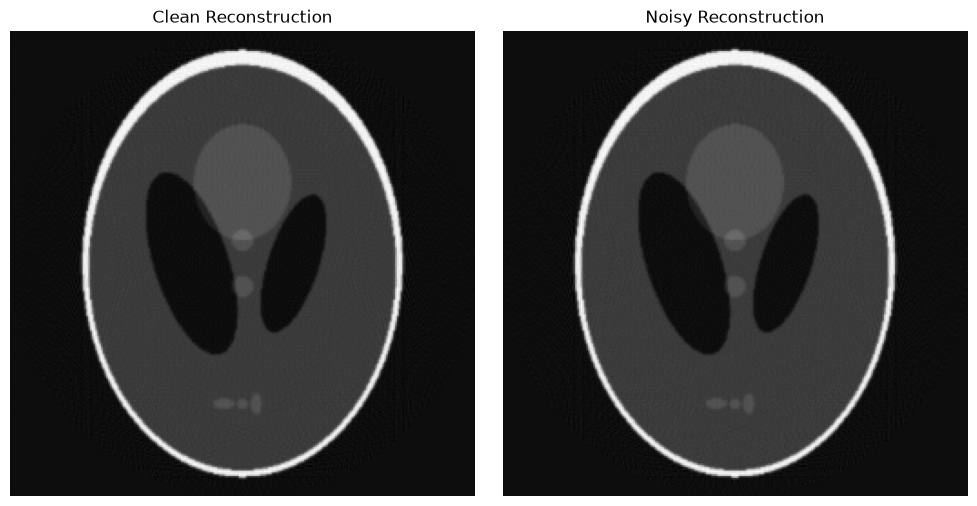

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(reconstruction_clean, cmap="gray")
axes[0].set_title("Clean Reconstruction")
axes[0].axis("off")

axes[1].imshow(reconstruction_noisy, cmap="gray")
axes[1].set_title("Noisy Reconstruction")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
psnr_noisy = psnr_noisy = calculate_psnr(phantom, reconstruction_noisy,)

ssim_noisy = calculate_ssim(phantom, reconstruction_noisy,)

print(f"Clean PSNR:  {psnr_clean:.2f} dB")
print(f"Noisy PSNR:  {psnr_noisy:.2f} dB")
print()
print(f"Clean SSIM:  {ssim_clean:.4f}")
print(f"Noisy SSIM:  {ssim_noisy:.4f}")

Clean PSNR:  30.77 dB
Noisy PSNR:  30.75 dB

Clean SSIM:  0.9218
Noisy SSIM:  0.9188


### Interpretación
Al añadir ruido con desviación estándar de 0.05, ambas métricas disminuyen. La reconstrucción sigue siendo visualmente parecida a la original, pero pierde algo de calidad.

In [9]:
noise_levels = [0.00, 0.01, 0.03, 0.05, 0.10]

results = []

for noise_std in noise_levels:
    noise = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=sinogram.shape,
    )

    noisy_sinogram = sinogram + noise

    reconstruction = iradon(
        noisy_sinogram,
        theta=theta,
        filter_name="ramp",
        circle=True,
    )

    psnr = calculate_psnr(phantom, reconstruction,)

    ssim = calculate_ssim(phantom, reconstruction,)

    results.append(
        {
            "noise_std": noise_std,
            "psnr": psnr,
            "ssim": ssim,
        }
    )

results

[{'noise_std': 0.0, 'psnr': 30.774607819876017, 'ssim': 0.9218287671580314},
 {'noise_std': 0.01, 'psnr': 30.772936253511823, 'ssim': 0.9216996915972233},
 {'noise_std': 0.03, 'psnr': 30.76560369823378, 'ssim': 0.9207900020751357},
 {'noise_std': 0.05, 'psnr': 30.756502488973744, 'ssim': 0.9187884672121406},
 {'noise_std': 0.1, 'psnr': 30.687923081084545, 'ssim': 0.9089117724229694}]

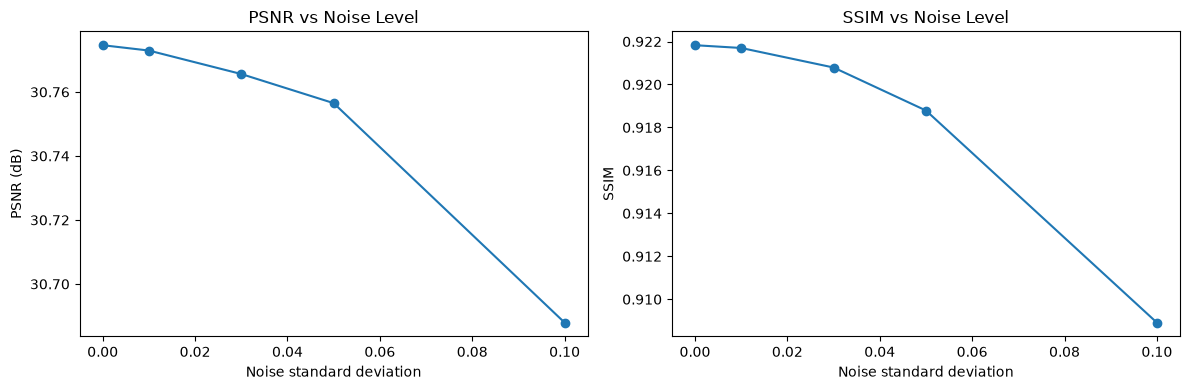

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    [result["noise_std"] for result in results],
    [result["psnr"] for result in results],
    marker="o",
)

axes[0].set_title("PSNR vs Noise Level")
axes[0].set_xlabel("Noise standard deviation")
axes[0].set_ylabel("PSNR (dB)")

axes[1].plot(
    [result["noise_std"] for result in results],
    [result["ssim"] for result in results],
    marker="o",
)

axes[1].set_title("SSIM vs Noise Level")
axes[1].set_xlabel("Noise standard deviation")
axes[1].set_ylabel("SSIM")

plt.tight_layout()
plt.show()

## 4. Conclusions

Gaussian noise was added to simulated CT projection data to evaluate its effect on filtered back projection (FBP).

Both PSNR and SSIM decreased as noise increased, indicating a gradual loss of reconstruction quality. The effect was moderate at low noise levels and more pronounced at the highest tested level.

This experiment demonstrates how acquisition noise can propagate through the reconstruction process. The simulation uses simplified Gaussian noise and does not fully reproduce the noise characteristics of a real CT scanner.

                 SHEPP-LOGAN
                      │
                      ▼
               RADON TRANSFORM
                      │
                      ▼
                  SINOGRAMA
                      │
             ┌────────┴────────┐
             │                 │
          limpio             ruido
             │                 │
             ▼                 ▼
            FBP               FBP
             │                 │
             ▼                 ▼
        reconstrucción    reconstrucción
             │                 │
             └────────┬────────┘
                      ▼
                 PSNR / SSIM